## Lindblad example
Welcome! This is a notebook that will guide you through the Lindblad.py package. We will have a look at a one spin-1/2 and a two spin-1/2 system to see how they behave and what functions are available. Feel free to copy this notebook and experiment with it.



### Import libraries

You will need the usual packages as well as `Qutip` and `scipy`. So far the Lindblad package has to be imported separately but it will be added to the SpinFinity main sooner or later.

You can find more information on the Qutip package and its installation here: https://qutip.readthedocs.io/en/latest/index.html.
The code uses the mesolve function to solve the Lindblad equation.

Scipy is needed for the Fourier transformation function.

In [ ]:
# import python libraries 
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const
import plotly
import scipy    # NEW

# import spin code and Lindblad package (not in main yet)
from spinsimulation import *
from spinsimulation import Lindblad as lind     # NEW

%load_ext autoreload
%autoreload 2

# import qutip code
from qutip import *     # NEW

## Overview of the available functions

The following functions are available in `Lindblad.py` and will be explained below:
- collapseOperators
- calcTimeEvolution
- plotTimeEvolution
- calcDecayTipfieldsweep
- plotDecayTipfieldsweep
- plotTipZeemanDiagramm
- calcDensityMatrix
- plotDensityMatrix
- calcTunnelCurrent_time
- plotTunnelCurrent_time
- calcFourierFreqs
- plotFourierFreqs

## One spin 1/2

We begin with a spin-1/2 in an external field. Then we look at the most important functions of Lindblad.py to understand the code structure. The expected eigenstates up and down are also displayed with `vis.plotEigenMatrix`.

In [ ]:
# initialize SpinSys object with magnetic fields and temperature
spinsys1 = SpinSys([0.5])
spinsys1.B = np.array([0, 0, 0.5])  # T
spinsys1.BTip = np.array([0, 0, 0]) # T
spinsys1.T = 1    # K

# define tunneling parameters
spinsys1.G_ss = [2e-9]*spinsys1.NSpins 
spinsys1.G=0.2e-9
spinsys1.G_tt = 1
spinsys1.V_DC = 0

# plot EigenMatrix
hamil.calcEigStates(spinsys1)
vis.plotEigenMatrix(spinsys1);

# QUESTION tip polarization -> only relevant for rates when there is a current

### Calculate and plot < Sz > (t)

To solve the Lindblad equation with `lind.calcTimeEvolution`, the system needs collapse operators. These are generated by `lind.collapseOperators` and stored as attributes of the `spinsys` object.

Because the collapse operators depend on eigenstates and rates, it is safer to recompute them (with the parameter recalcRates=True) after any parameter change that can affect the Hamiltonian or the tunneling rates.

To get time-dependent results, always run `lind.calcTimeEvolution` first. It stores the following attributes:

- `spinsys.timeEvolution_result`: the QuTiP `mesolve` result that contains the time values and the system's density matrix at each     time step.
- `spinsys.timeEvolution_spinidx`: the indices of the spins for which the time evolution was calculated. In our case it is 0 and by default all spins are considered.
- `spinsys.timeEvolution_Saxis`: the spin operator of which the expectation values were calculated based on the density matrices (default is `Sz`).

From these attributes, the time evolution, density matrices, Fourier transformation and current can be plotted. So keep that the last  `lind.calcTimeEvolution` that you ran is the base for the other time-dependent functions.

C:\Users\Philip\Desktop\VSCode\ternes_ldos\spinsimulation\calcBath.py:438: RuntimeWarning:

invalid value encountered in scalar divide

c:\Users\Philip\.conda\envs\library_development\Lib\site-packages\qutip\solver\solver_base.py:598: FutureWarning:

e_ops will be keyword only from qutip 5.3 for all solver



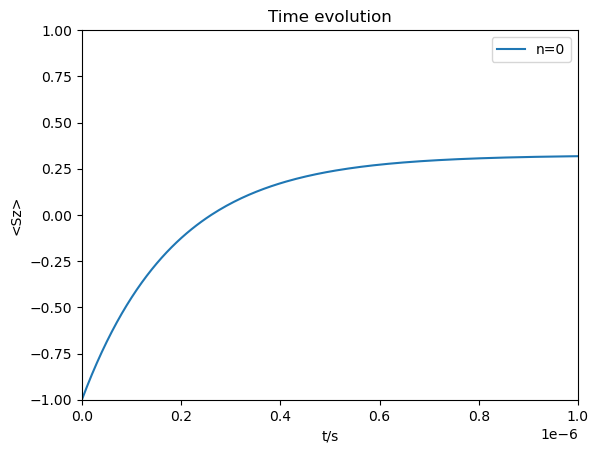

T2=200 s


In [ ]:
# calc and plot time evolution
psi_exc = np.array([0, 1])    # define excited state
lind.calcTimeEvolution(spinsys1, psi_0=psi_exc, timeRange=[0, 1e-6], N_times=200)   # calculate the time evolution for a specific time range. 
lind.plotTimeEvolution(spinsys1);   # plot the calculated time evolution
print(f'T2={spinsys1.T2} s')    # TODO QUESTION is T2 decay time?? Or what is it in ns??

We see an exponential relaxation of a fully excited spin state towards thermal equilibrium.

Let's try the same thing with `T=0.0001` K and observe the end state. Notice that we need a longer time frame here to capture the whole relaxation process as it is slower for lower temperatures.

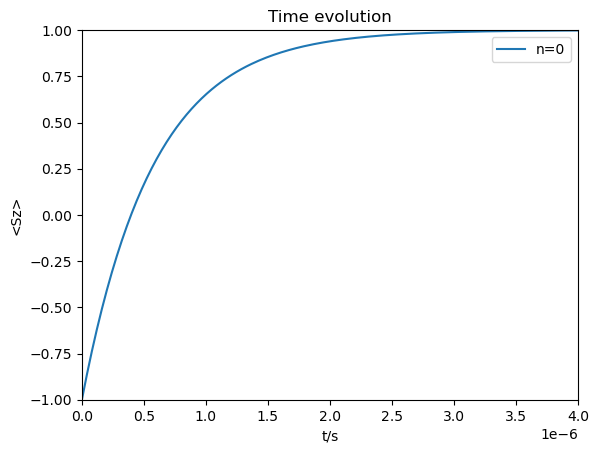

In [5]:
# same thing with very low temperature
spinsys1.T = 0.0001 # K
lind.collapseOperators(spinsys1)
lind.calcTimeEvolution(spinsys1, psi_0=psi_exc, timeRange=[0, 4e-6], N_times=200)
lind.plotTimeEvolution(spinsys1);

For very low temperatures, the spin relaxes towards the ground state. We can now investigate what a different initial state leads to. 

We start in a superposition of the eigenstates and return to `T = 1`K. The relaxation is still exponential but the initial value of <Sz> should be different. For multiple coupled spins, this could result in oscillating behaviour, but for this single-spin case, the main visible difference is the initial condition. The end state is the same as the example above with the same temperature.

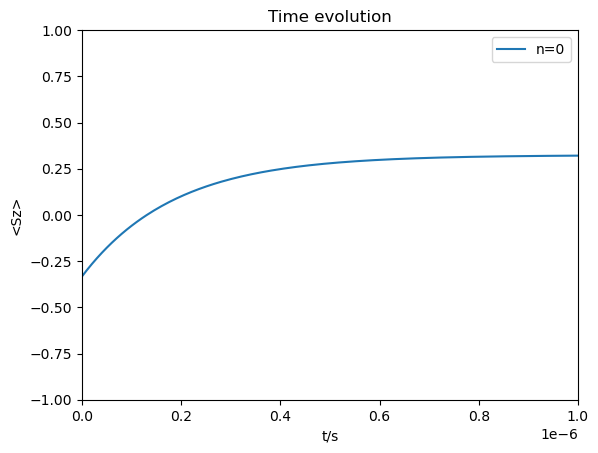

In [7]:
# higher temperature again but superposition initial state
spinsys1.T = 1
psi_mix = np.sqrt(1/3)*np.array([1, 0]) + np.sqrt(2/3)*np.array([0, 1]) # define superposition state
lind.collapseOperators(spinsys1)
lind.calcTimeEvolution(spinsys1, psi_0=psi_mix, timeRange=[0, 1e-6], N_times=200)
lind.plotTimeEvolution(spinsys1);

### Tip field sweep

We can now plot a tip field sweep using `lind.plotDecayTipfieldsweep` to see if a different behaviour occurs for a non-zero tip field. But our single spin is unfortunately too boring for that. 

In general one needs to be careful when choosing the number of time and BTip field steps (`N_times`and `N_BTip`). The plot can be misleading and mesolve possibly doesn't converge if there are too little steps. On the other hand, increasing the steps also increases the calculation time.

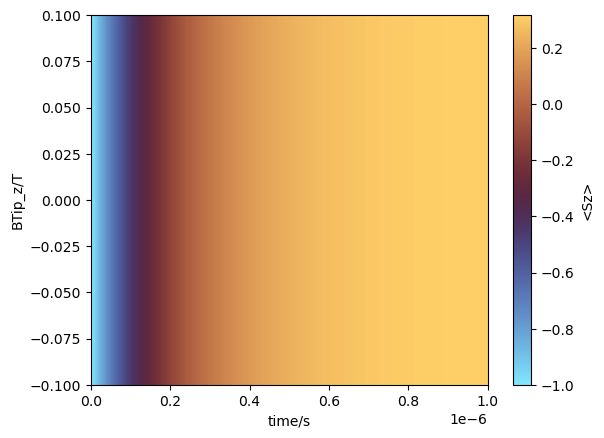

In [9]:
lind.plotDecayTipfieldsweep(spinsys1, psi_0=psi_exc, timeRange = [0, 1e-6], N_times=200, BTipRange = [-0.1, 0.1], N_BTip=200);

## Two coupled spin-1/2

We can now look at a more dynamic system of two coupled spin-1/2 with B = [0, 0, 0.5] T external field, tip field and 2 GHz exchange coupling. We can first have a look at the system without tip field and plot the eigenmatrix and tip field Zeeman diagram.

In [14]:
# initialize SpinSys object 
spinsys2 = SpinSys([0.5, 0.5])
spinsys2.B = np.array([0, 0, 0.5])  # T
spinsys2.BTip = np.array([0, 0, 0]) # T
spinsys2.T = 0.3    # K
spinsys2.Jvector[0, :] = np.array([2, 2, 2])*spinsys2.GHztomeVConversion

# define tunneling parameters
spinsys2.G_ss = [2e-9]*spinsys2.NSpins 
spinsys2.G=0.2e-9
spinsys2.G_tt = 1
spinsys2.V_DC = 0

# plot EigenMatrix
hamil.calcEigStates(spinsys2)
vis.plotEigenMatrix(spinsys2);
lind.plotTipZeemanDiagramm(spinsys2, BTipRange=[-0.1, 0.1], N_BTip=200);